## Sky Model 

This notebook contains synthetic models used in interferometric imaging. All models return flux-normalized sky brightness images.

In [1]:
#| default_exp sky_models

In [2]:
#| export
import numpy as np
def make_coordinate_grid(npix, fov_mas):
    """
    Generate 2D coordinate grids in radians for a given field of view and image size.

    Parameters
    ----------
    npix : int
        Number of pixels along one axis (image will be npix x npix).
    fov_mas : float
        Field of view in milliarcseconds.

    Returns
    -------
    L : ndarray
        2D coordinate grid for x-axis in radians.
    M : ndarray
        2D coordinate grid for y-axis in radians.   
    dx : float
        Pixel size in radians.
    """
    fov_rad = fov_mas * np.pi / (180 * 3600 * 1000)  # Convert to radians
    dx = fov_rad / npix
    l = (np.arange(npix) - npix // 2) * dx
    m = (np.arange(npix) - npix // 2) * dx
    L, M = np.meshgrid(l, m, indexing='ij')
    return L, M, dx

In [3]:
#| export
def make_gaussian(L, M, fwhm_mas, x0_mas=0.0, y0_mas=0.0):
    """
    Generate a symmetric 2D Gaussian centered at specified coordinates.

    Parameters
    ----------
    L : ndarray
        2D coordinate grid for x-axis in radians.
    M : ndarray
        2D coordinate grid for y-axis in radians.
    fwhm_mas : float
        Full width at half maximum of the Gaussian in milliarcseconds.
    x0_mas, y0_mas : float, optional
        Center coordinates of the Gaussian in milliarcseconds. Default is (0, 0).

    Returns
    -------
    gaussian : ndarray
        2D normalized Gaussian image.
    """
    x0 = x0_mas * np.pi / (180 * 3600 * 1000)
    y0 = y0_mas * np.pi / (180 * 3600 * 1000)
    fwhm_rad = fwhm_mas * np.pi / (180 * 3600 * 1000)
    sigma = fwhm_rad / (2 * np.sqrt(2 * np.log(2)))
    R = np.sqrt((L - x0)**2 + (M - y0)**2)
    gaussian = np.exp(-0.5 * (R / sigma)**2)
    return gaussian / np.sum(gaussian)

In [4]:
#| export
def make_disk(L, M, radius_mas, x0_mas=0.0, y0_mas=0.0):
    """
    Generate a uniform circular disk model.

    Parameters
    ----------
    L : ndarray
        2D coordinate grid for x-axis in radians.
    M : ndarray
        2D coordinate grid for y-axis in radians.
    radius_mas : float
        Radius of the disk in milliarcseconds.
    x0_mas, y0_mas : float, optional
        Center position of the disk in milliarcseconds.

    Returns
    -------
    disk : ndarray
        2D disk model image.
    """
    x0 = x0_mas * np.pi / (180 * 3600 * 1000)
    y0 = y0_mas * np.pi / (180 * 3600 * 1000)
    radius_rad = radius_mas * np.pi / (180 * 3600 * 1000)
    R = np.sqrt((L - x0)**2 + (M - y0)**2)
    disk = (R <= radius_rad).astype(float)
    return disk / np.sum(disk)

In [5]:
#| export
def make_ring(L, M, inner_mas, outer_mas, x0_mas=0.0, y0_mas=0.0):
    """
    Generate a ring-like brightness distribution (annulus).

    Parameters
    ----------
    L : ndarray
        2D coordinate grid for x-axis in radians.
    M : ndarray
        2D coordinate grid for y-axis in radians.
    inner_radius_mas : float
        Inner radius of the ring in milliarcseconds.
    outer_radius_mas : float
        Outer radius of the ring in milliarcseconds.
    x0_mas, y0_mas : float, optional
        Center position of the ring in milliarcseconds.

    Returns
    -------
    ring : ndarray
        2D ring-shaped image.
    """    
    x0 = x0_mas * np.pi / (180 * 3600 * 1000)
    y0 = y0_mas * np.pi / (180 * 3600 * 1000)
    inner_rad = inner_mas * np.pi / (180 * 3600 * 1000)
    outer_rad = outer_mas * np.pi / (180 * 3600 * 1000)
    R = np.sqrt((L - x0)**2 + (M - y0)**2)
    ring = np.logical_and(R >= inner_rad, R <= outer_rad).astype(float)
    return ring / np.sum(ring)

In [6]:
#| export
def make_gaussian_elong(L, M, fwhm_minor_mas, axis_ratio=1.0, pa_deg=0.0, x0_mas=0.0, y0_mas=0.0):
    """
    Generate an elliptical Gaussian brightness distribution.

    Parameters
    ----------
    L : ndarray
        2D coordinate grid for x-axis in radians.
    M : ndarray
        2D coordinate grid for y-axis in radians.
    fwhm_minor_mas : float
        FWHM along the minor axis (in milliarcseconds).
    ratio : float
        Axis ratio = major / minor.
    x0_mas, y0_mas : float, optional
        Center position of the Gaussian in milliarcseconds.
    pa_deg : float, optional
        Position angle in degrees, measured from North to East (counter-clockwise).

    Returns
    -------
    elliptical_gaussian : ndarray
        2D elliptical Gaussian image.
    """
    # Convert to radians
    x0 = x0_mas * np.pi / (180 * 3600 * 1000)
    y0 = y0_mas * np.pi / (180 * 3600 * 1000)
    fwhm_minor = fwhm_minor_mas * np.pi / (180 * 3600 * 1000)
    fwhm_major = axis_ratio * fwhm_minor
    sigma_minor = fwhm_minor / (2 * np.sqrt(2 * np.log(2)))
    sigma_major = fwhm_major / (2 * np.sqrt(2 * np.log(2)))

    # Position angle in radians
    theta = np.deg2rad(90 - pa_deg)

    # Shift coordinates
    X = L - x0
    Y = M - y0

    # Rotate coordinates
    X_rot = X * np.cos(theta) + Y * np.sin(theta)
    Y_rot = -X * np.sin(theta) + Y * np.cos(theta)

    # Elliptical Gaussian
    gaussian = np.exp(-0.5 * ((X_rot / sigma_major)**2 + (Y_rot / sigma_minor)**2))

    # Normalize
    return gaussian / np.sum(gaussian)

### Example: the model gallery

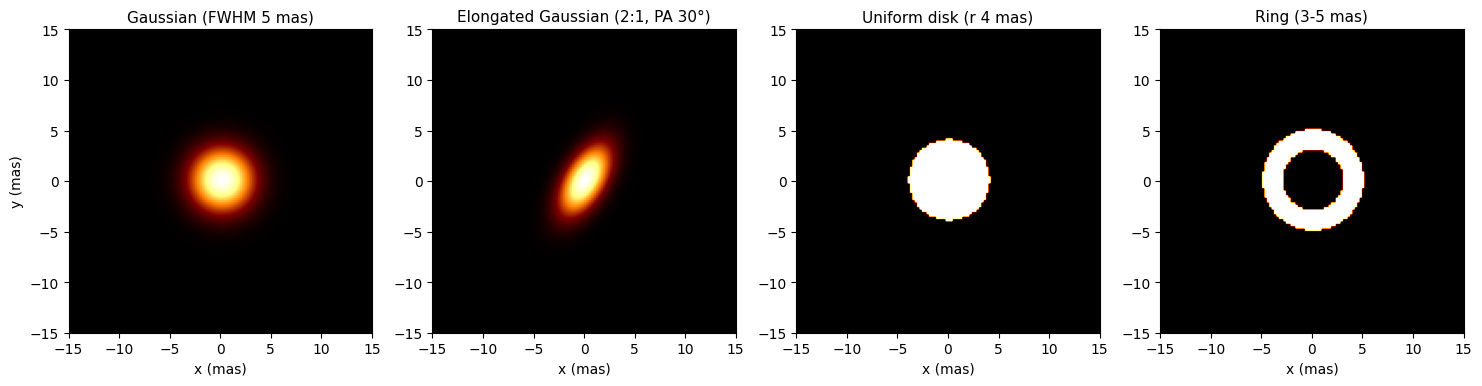

In [7]:
import matplotlib.pyplot as plt

npix, fov_mas = 128, 30
L, M, dx = make_coordinate_grid(npix, fov_mas)
models = {
    'Gaussian (FWHM 5 mas)'             : make_gaussian(L, M, 5),
    'Elongated Gaussian (2:1, PA 30°)'  : make_gaussian_elong(L, M, 3, axis_ratio=2, pa_deg=30),
    'Uniform disk (r 4 mas)'            : make_disk(L, M, 4),
    'Ring (3-5 mas)'                    : make_ring(L, M, 3, 5),
}
ext = [-fov_mas/2, fov_mas/2, -fov_mas/2, fov_mas/2]
fig, axs = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, (name, img) in zip(axs, models.items()):
    ax.imshow(img.T, origin='lower', extent=ext, cmap='afmhot'); ax.set_title(name, fontsize=11)
    ax.set_xlabel('x (mas)')
axs[0].set_ylabel('y (mas)')
plt.show()